# Automated PCB Defect Detection Using Classical Image Processing Techniques

ARTI 403 - Image Processing | Group 2

## Thresholding and Morphology

This notebook turns the difference image (test image minus template) into a black and white mask where the defects are white. It tries three threshold methods (fixed, Otsu, and adaptive), then cleans the mask with opening (removes small white dots) and closing (fills small holes). The kernel size and the other settings can be changed for the experiments. The mask is then used by the contour part to draw the bounding boxes.

### 1. Download the dataset

The cell downloads DeepPCB from GitHub if the folder is not here yet.

In [1]:
import os

if not os.path.exists("DeepPCB"):
    !git clone https://github.com/tangsanli5201/DeepPCB.git

Cloning into 'DeepPCB'...
remote: Enumerating objects: 4753, done.
remote: Counting objects: 100% (14/14), done.
remote: Compressing objects: 100% (2/2), done.
remote: Total 4753 (delta 13), reused 12 (delta 12), pack-reused 4739 (from 1)
Receiving objects: 100% (4753/4753), 85.81 MiB | 13.60 MiB/s, done.
Resolving deltas: 100% (191/191), done.
Updating files: 100% (4548/4548), done.


### 2. Data loading functions

The same functions from the data loading part. They are here so this notebook can run on its own.

In [2]:
import os
import cv2
from collections import Counter

# path to the dataset folder
ROOT = "DeepPCB/PCBData"

# defect type numbers from the annotation files
NAMES = {1: "open", 2: "short", 3: "mousebite", 4: "spur", 5: "copper", 6: "pin-hole"}
# only open and short for our project
KEEP = {1, 2}


# reads trainval.txt or test.txt
def list_samples(split="train"):
    fname = "trainval.txt" if split == "train" else "test.txt"
    samples = []
    with open(os.path.join(ROOT, fname)) as f:
        for line in f:
            parts = line.replace(",", " ").split()
            if len(parts) >= 2:
                samples.append((parts[0].replace(".jpg", ""), parts[1]))
    return samples


# returns test image, template and boxes (x1, y1, x2, y2, type)
def load_pair(sample):
    img_path, ann_path = sample
    test = cv2.imread(os.path.join(ROOT, img_path + "_test.jpg"), cv2.IMREAD_GRAYSCALE)
    temp = cv2.imread(os.path.join(ROOT, img_path + "_temp.jpg"), cv2.IMREAD_GRAYSCALE)

    boxes = []
    with open(os.path.join(ROOT, ann_path)) as f:
        for line in f:
            p = line.replace(",", " ").split()
            if len(p) == 5 and int(p[4]) in KEEP:
                boxes.append((int(p[0]), int(p[1]), int(p[2]), int(p[3]), int(p[4])))
    return test, temp, boxes


# number of defects per type
def stats(split="train"):
    counter = Counter()
    for s in list_samples(split):
        _, _, boxes = load_pair(s)
        counter.update(NAMES[b[4]] for b in boxes)
    return counter


# saves the images we use in the report
def save_example(sample, out_dir="examples", name="example"):
    os.makedirs(out_dir, exist_ok=True)
    test, temp, boxes = load_pair(sample)

    # green boxes = ground truth
    vis = cv2.cvtColor(test, cv2.COLOR_GRAY2BGR)
    for x1, y1, x2, y2, t in boxes:
        cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(vis, NAMES[t], (x1, max(y1 - 4, 10)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)

    cv2.imwrite(os.path.join(out_dir, f"{name}_template.png"), temp)
    cv2.imwrite(os.path.join(out_dir, f"{name}_test.png"), test)
    cv2.imwrite(os.path.join(out_dir, f"{name}_gt.png"), vis)

### 3. Thresholding and morphology

`make_mask` takes the difference image and returns a mask of 0 and 255.

- `method`: `fixed`, `otsu`, or `adaptive`
- `thresh`: threshold value for the fixed method
- `block` and `c`: window size and constant for the adaptive method
- `k`: kernel size for opening and closing (3, 5, or 7)
- `morph`: turns opening and closing on or off

`save_examples` saves the pictures for the report.

In [3]:
import os
import cv2
import numpy as np

# default settings, the experiments part changes them
THRESH = 50
BLOCK = 31
C = -25
KERNEL = 3


# diff = grayscale difference image (uint8)
# returns a mask of 0 and 255
def make_mask(diff, method="otsu", thresh=THRESH, block=BLOCK, c=C, k=KERNEL, morph=True):
    if method == "fixed":
        _, mask = cv2.threshold(diff, thresh, 255, cv2.THRESH_BINARY)
    elif method == "otsu":
        _, mask = cv2.threshold(diff, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    elif method == "adaptive":
        # c is negative because the diff image is mostly black
        mask = cv2.adaptiveThreshold(diff, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                     cv2.THRESH_BINARY, block, c)
    else:
        raise ValueError("method must be fixed, otsu or adaptive")

    if morph and k > 1:
        kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (k, k))
        # opening removes small white dots, closing fills small holes
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    return mask


# adds a title on the image and makes it 3 channels
def label(img, title):
    out = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    cv2.putText(out, title, (6, 22), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
    return out


# cuts a window around the defect box and makes it bigger so it is easy to see
def crop(img, box, size=160, scale=3):
    x1, y1, x2, y2 = box[:4]
    cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
    x0 = int(np.clip(cx - size // 2, 0, img.shape[1] - size))
    y0 = int(np.clip(cy - size // 2, 0, img.shape[0] - size))
    win = img[y0:y0 + size, x0:x0 + size]
    return cv2.resize(win, None, fx=scale, fy=scale, interpolation=cv2.INTER_NEAREST)


# saves two pictures for the report: the three methods, and before/after morphology
def save_examples(diff, box, out_dir="examples", name="threshold"):
    os.makedirs(out_dir, exist_ok=True)

    panels = [label(crop(diff, box), "difference")]
    for m in ("fixed", "otsu", "adaptive"):
        panels.append(label(crop(make_mask(diff, m), box), m))
    grid = np.vstack([np.hstack(panels[:2]), np.hstack(panels[2:])])
    cv2.imwrite(os.path.join(out_dir, f"{name}_methods.png"), grid)

    before = label(crop(make_mask(diff, "otsu", morph=False), box), "otsu, no morphology")
    after = label(crop(make_mask(diff, "otsu"), box), "otsu + opening/closing")
    cv2.imwrite(os.path.join(out_dir, f"{name}_morphology.png"), np.hstack([before, after]))

### 4. Example

The difference image here is temporary (Gaussian blur, then `absdiff`) until the preprocessing part is ready. The cell prints the number of white pixels for each method and saves the pictures.

In [4]:
for s in list_samples("train"):
    test, temp, boxes = load_pair(s)
    if boxes:
        break
diff = cv2.absdiff(cv2.GaussianBlur(test, (3, 3), 0), cv2.GaussianBlur(temp, (3, 3), 0))

for m in ("fixed", "otsu", "adaptive"):
    mask = make_mask(diff, m)
    print(m, "white pixels:", int((mask > 0).sum()))
save_examples(diff, boxes[0])

fixed white pixels: 3570
otsu white pixels: 3928
adaptive white pixels: 3980


### 5. Results

Left: the three methods compared. Right: Otsu before and after opening and closing.

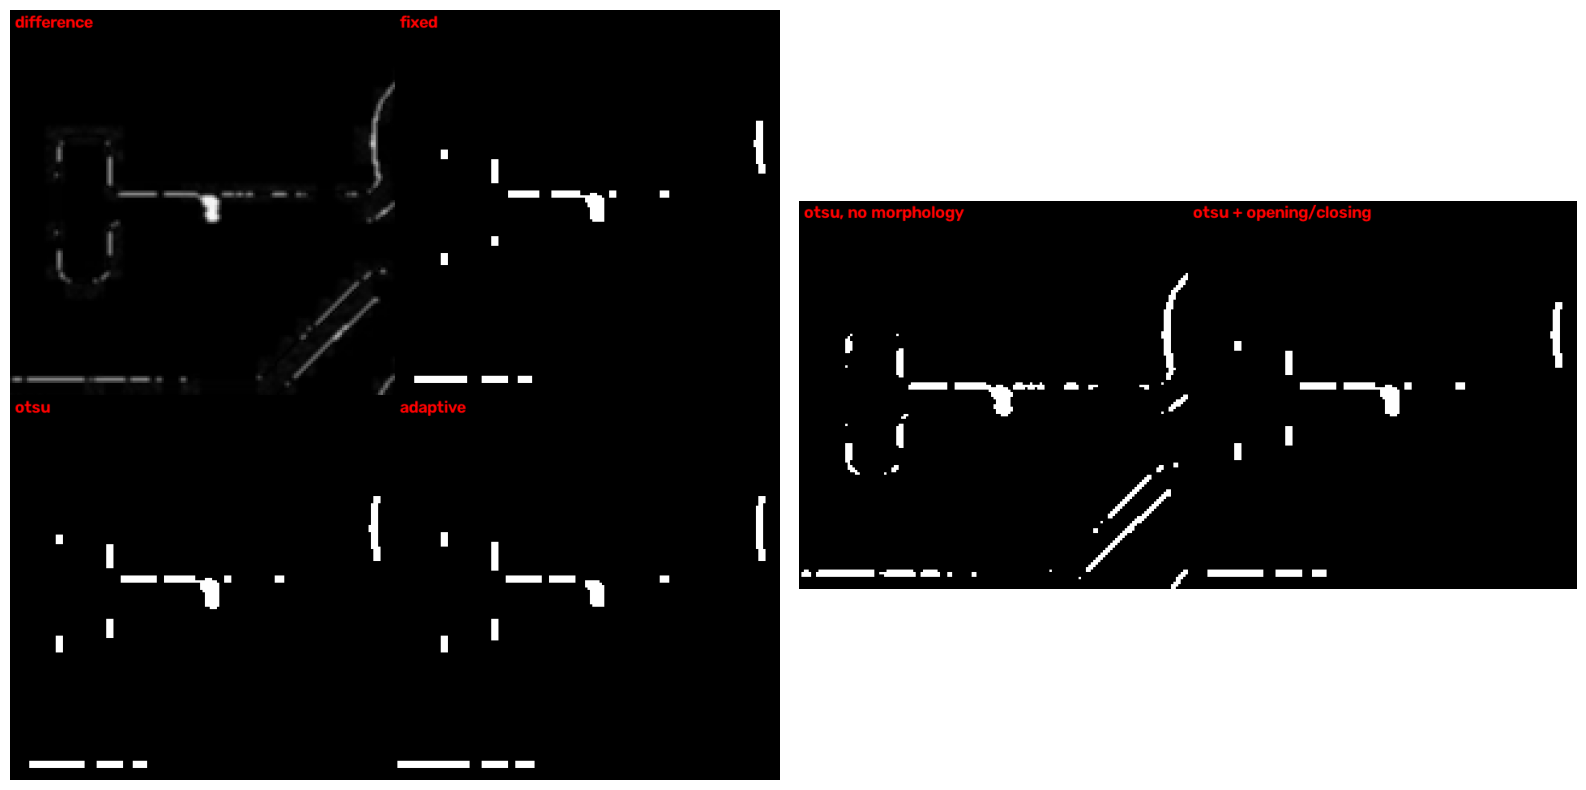

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, f in zip(axes, ["threshold_methods", "threshold_morphology"]):
    ax.imshow(cv2.cvtColor(cv2.imread(f"examples/{f}.png"), cv2.COLOR_BGR2RGB))
    ax.axis("off")
plt.tight_layout()
plt.show()